In [4]:
##### Figure SI: exposure distribution with p10-p90 uncertainty bands

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

In [5]:
##### LOAD DATA

ROOT = Path.cwd().parent
dist_df = pd.read_csv(ROOT / "Results/30x30/exposure_by_deprivation_percentile.csv")

FIG_DIR = ROOT / "Figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [6]:
##### STYLING AND HELPERS

COLORS = {
    "Capital": "#2F7C87",
    "Labor": "#C96A3B",
    "Production": "#E5E5E5",
}
PRODUCTION_EDGE = "#C4C4C4"
REFERENCE_COLOR = "#888888"

def smooth(series, window=9, polyorder=2):
    smoothed = savgol_filter(series.values, window_length=window, polyorder=polyorder, mode="interp")
    return pd.Series(smoothed, index=series.index)

def get_series(basis, region, variable, area, estimate="core"):
    sub = dist_df[
        (dist_df["pctl_basis"] == basis) & (dist_df["region"] == region)
        & (dist_df["variable"] == variable) & (dist_df["area"] == area)
        & (dist_df["estimate"] == estimate)
    ].sort_values("percentile")
    return smooth(sub.set_index("percentile")["pct_of_total"])

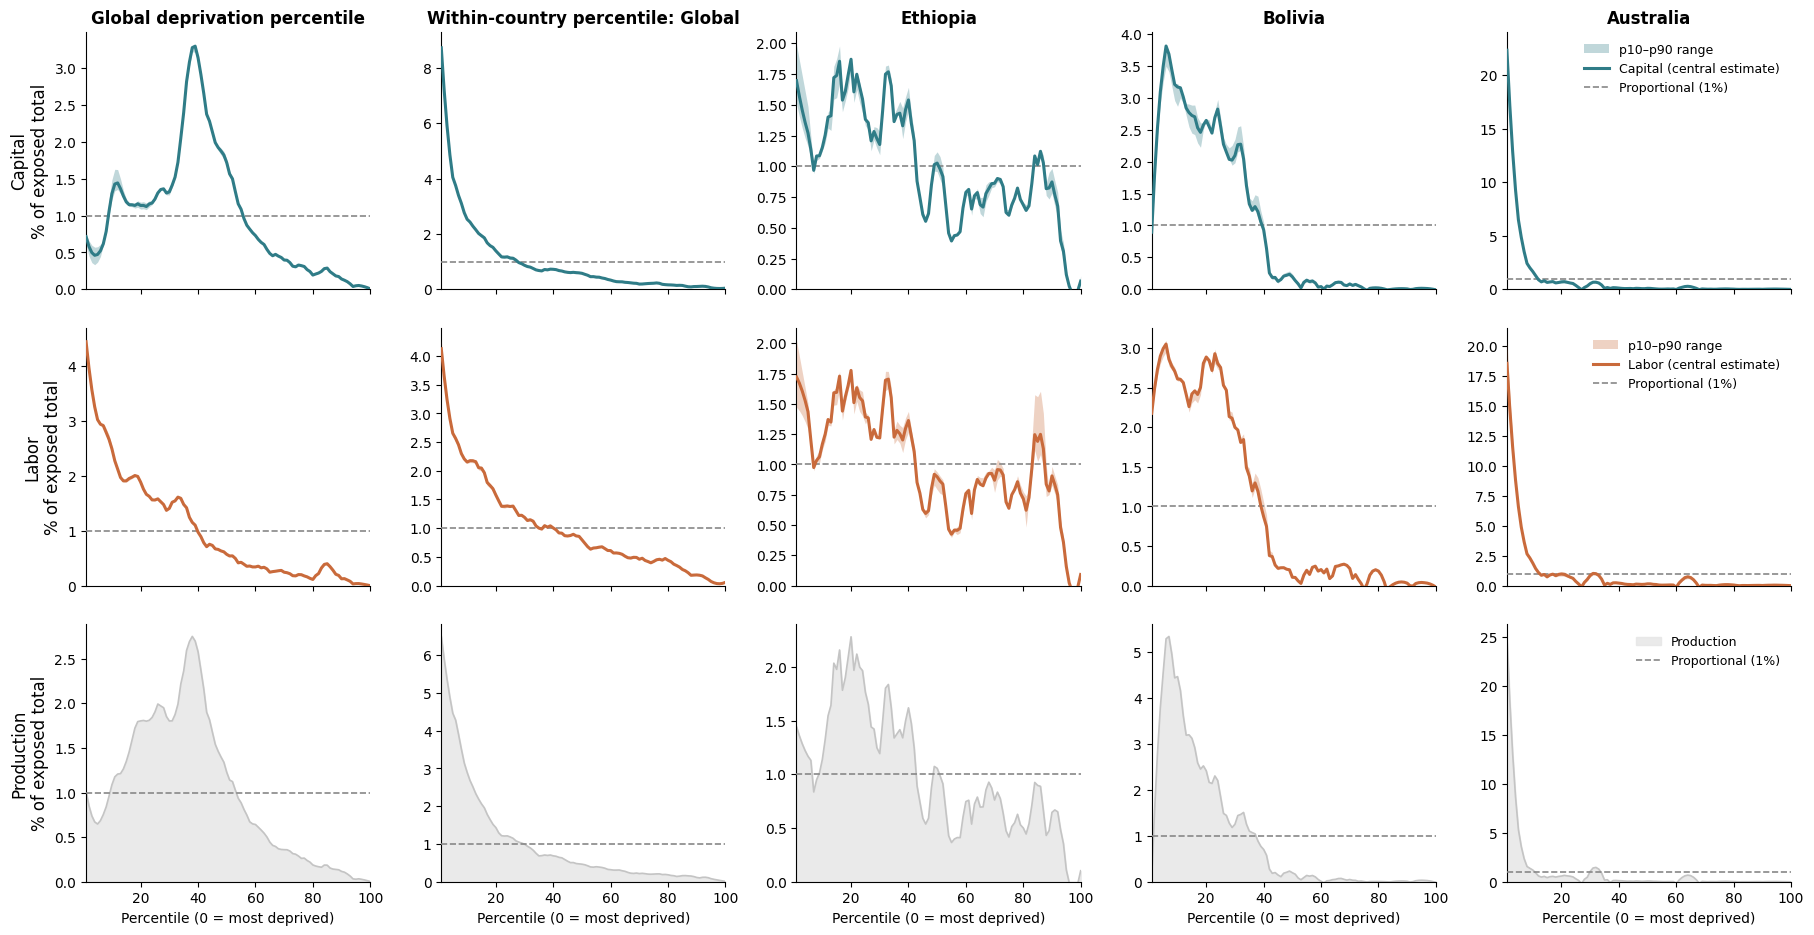

In [7]:
##### FIGURE SI

##### SPECS

# rows: variables (production has no uncertainty estimates)
ROW_VARS = ["Capital", "Labor", "Production"]

# columns: (column title, percentile basis, region)
COL_SPECS = [
    ("Global deprivation percentile",     "global",   "Global"),
    ("Within-country percentile: Global", "national", "Global"),
    ("Ethiopia",                          "national", "ETH"),
    ("Bolivia",                           "national", "BOL"),
    ("Australia",                         "national", "AUS"),
]

fig, axes = plt.subplots(3, 5, figsize=(22, 10), sharey=False, sharex=True)

for r, var_name in enumerate(ROW_VARS):
    for c, (col_title, basis, region) in enumerate(COL_SPECS):
        ax = axes[r, c]
        central = get_series(basis, region, var_name, "exposed", "core")

        if var_name == "Production":
            ax.fill_between(central.index, central.values, color=COLORS["Production"],
                            alpha=0.8, zorder=1, label="Production")
            ax.plot(central.index, central.values, color=PRODUCTION_EDGE,
                    linewidth=1.2, zorder=2)
        else:
            lo = get_series(basis, region, var_name, "exposed", "p10")
            hi = get_series(basis, region, var_name, "exposed", "p90")

            band_lo = np.minimum(np.minimum(lo.values, hi.values), central.values)
            band_hi = np.maximum(np.maximum(lo.values, hi.values), central.values)

            ax.fill_between(central.index, band_lo, band_hi,
                            color=COLORS[var_name], alpha=0.3, linewidth=0, zorder=3,
                            label="p10–p90 range")
            ax.plot(central.index, central.values, color=COLORS[var_name],
                    linewidth=2.2, zorder=4, label=f"{var_name} (central estimate)")

        ax.axhline(1, color=REFERENCE_COLOR, linewidth=1.2, linestyle="--", zorder=3,
                   label="Proportional (1%)")

        ax.set_xlim(1, 100)
        ax.set_ylim(bottom=0)
        ax.spines[["top", "right"]].set_visible(False)
        ax.tick_params(labelsize=10)

        if r == 0:
            ax.set_title(col_title, fontweight="bold", fontsize=12)
        if c == 0:
            ax.set_ylabel(f"{var_name}\n% of exposed total", fontsize=12)
        if r == len(ROW_VARS) - 1:
            ax.set_xlabel("Percentile (0 = most deprived)", fontsize=10)
        if c == len(COL_SPECS) - 1:
            ax.legend(frameon=False, fontsize=9, loc="upper right")

fig.subplots_adjust(hspace=0.15, wspace=0.25, top=0.93, bottom=0.08)
plt.savefig(FIG_DIR / "Figure_SI_exposure_distribution_CI.tiff", dpi=300, bbox_inches="tight")
plt.show()